[![Ouvrir dans Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DEDJIABDOUL/omicaa-lab-machine-learning-bioinformatics/blob/main/notebooks/07_projet_integrateur_bioinformatique.ipynb)

# Notebook 07 : projet intégrateur, classification de leucémies à partir de l'expression génique

**Omicaa Lab | Machine Learning et Deep Learning pour les biologistes** | Auteur : DEDJI ABDOUL BATINOU

## Introduction scientifique

Les données transcriptomiques cumulent trois difficultés absentes du jeu Wisconsin : une dimensionnalité extrême (des milliers de gènes pour quelques dizaines d'échantillons), un effectif de test minuscule et un risque majeur de fuite d'information par sélection de variables. Ce projet applique l'intégralité du pipeline des notebooks précédents à un second jeu de données, celui de Golub et collaborateurs (1999), qui distingue la leucémie aiguë lymphoblastique (ALL) de la leucémie aiguë myéloïde (AML) à partir de puces à ADN. La capacité à transférer une méthode est la compétence finale visée.

## Objectifs techniques

1. Contrôler et explorer une matrice d'expression où le nombre de variables dépasse largement le nombre d'observations.
2. Concevoir un pipeline avec sélection de gènes interne à la validation, sans fuite d'information.
3. Démontrer expérimentalement la fuite induite par une sélection de variables faite avant le découpage.
4. Comparer plusieurs modèles par validation croisée imbriquée, puis évaluer une seule fois sur un petit test avec intervalle de confiance.
5. Documenter les limites et distinguer performance prédictive, association statistique et conclusion biologique.

## Prérequis

* Notebooks 03 à 05 terminés.
* Accès Internet pour télécharger le fichier de données (environ 1,2 Mo).

## Résultat attendu

Un pipeline reproductible pour 72 profils d'expression, une démonstration chiffrée de la fuite par sélection de gènes, une évaluation finale avec intervalles de confiance, un modèle sauvegardé et rechargé, et un bilan critique des limites.

## 1. Contrôle de l'environnement

In [1]:
import sys, platform, random
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import json, warnings, hashlib, urllib.request
from pathlib import Path
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Python      :", platform.python_version())
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("Matplotlib  :", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)

Python      : 3.12.3
NumPy       : 2.4.4
pandas      : 3.0.2
Matplotlib  : 3.10.8
scikit-learn: 1.8.0


In [2]:
try:
    import rdata                         # lecture des fichiers .RData
except ImportError:
    %pip install -q rdata
    import rdata
import joblib
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_score, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve, ConfusionMatrixDisplay)

FIG, RES, MOD, CACHE = Path("figures"), Path("results"), Path("models"), Path("data/cache")
for d in (FIG, RES, MOD, CACHE): d.mkdir(parents=True, exist_ok=True)
ROUGE, CYAN, NOIR, GRIS = "#FF0000", "#0097B2", "#000000", "#8A8A8A"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelsize": 9.5, "font.size": 9.5})
JOURNAL = {"notebook": "07", "graine": SEED, "sklearn": sklearn.__version__}

## 2. Choix du jeu de données et provenance

**Étude d'origine.** T. R. Golub et al., *Molecular classification of cancer: class discovery and class prediction by gene expression monitoring*, Science, 286(5439), 531-537, 1999. Profils d'expression de 72 échantillons de patients atteints de leucémie aiguë (47 ALL, 25 AML), mesurés sur puces Affymetrix et comprenant 7129 sondes.

**Pourquoi ce jeu de données.** Il est de taille compatible avec un CPU, bien documenté dans la littérature, et il concentre les difficultés pédagogiques visées : $p \gg n$ (7129 variables pour 72 échantillons, soit environ 99 variables par échantillon), classes déséquilibrées (47 contre 25), nécessité de sélectionner des variables sans fuite. Ce n'est pas un choix de popularité : c'est le plus petit cas qui oblige à raisonner sur la validation.

**Source d'accès utilisée ici.** Les serveurs NCBI GEO et UCI n'étaient pas joignables depuis l'environnement dans lequel ce notebook a été validé (réponse HTTP 403). Le fichier est donc récupéré depuis une copie publique hébergée sur GitHub (dépôt `ramhiser/datamicroarray`, fichier `data/golub.RData`), qui redistribue les données de l'étude d'origine. Cette copie est un **miroir de commodité** : sa licence n'a pas été vérifiée et elle ne remplace pas la publication d'origine, qui reste la référence à citer. Une reproduction à partir d'une série GEO officielle est proposée en extension. La somme de contrôle du fichier est affichée pour détecter toute altération.

In [3]:
URL = "https://raw.githubusercontent.com/ramhiser/datamicroarray/master/data/golub.RData"
fichier = CACHE / "golub.RData"
if not fichier.exists():
    urllib.request.urlretrieve(URL, fichier)

octets = fichier.read_bytes()
sha = hashlib.sha256(octets).hexdigest()
print("taille du fichier :", len(octets), "octets")
print("SHA-256           :", sha)
assert len(octets) > 1_000_000, "fichier trop petit : téléchargement incomplet ?"

taille du fichier : 1191760 octets
SHA-256           : 594f5507597fb2352d210c803a88a218fbf6d1f2705372029e5738815216747b


## 3. Chargement et validation des entrées (étape B)

In [4]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")           # avertissement d'encodage sans conséquence
    conv = rdata.conversion.convert(rdata.parser.parse_file(fichier))
g = conv["golub"]

X = g["x"].to_pandas()
X.index = X.index.astype(str); X.columns = X.columns.astype(str)
X.index.name, X.columns.name = None, None
etiquette = pd.Series(np.asarray(g["y"]).astype(str), index=X.index, name="classe")
y = (etiquette == "AML").astype(int).rename("AML")            # classe positive : AML (1) ; ALL (0)

print("matrice d'expression :", X.shape, "(échantillons, sondes)")
print(etiquette.value_counts().to_dict())
print("exemples d'identifiants de sondes :", list(X.columns[:3]), "...")

assert X.shape == (72, 7129)
assert X.index.is_unique and X.columns.is_unique
assert X.isna().sum().sum() == 0 and np.isfinite(X.values).all()
assert set(etiquette.unique()) == {"ALL", "AML"} and (y.sum(), (1 - y).sum()) == (25, 47)
assert X.index.equals(y.index)
assert not any(c in ("classe", "AML") for c in X.columns)       # la cible n'est pas parmi les caractéristiques
print("ratio p / n :", round(X.shape[1] / X.shape[0], 1))

matrice d'expression : (72, 7129) (échantillons, sondes)
{'ALL': 47, 'AML': 25}
exemples d'identifiants de sondes : ['AFFX-BioB-5_at', 'AFFX-BioB-M_at', 'AFFX-BioB-3_at'] ...
ratio p / n : 99.0


## 4. Contrôle qualité et exploration

Le jeu a été chargé sans valeur manquante. On examine l'échelle des valeurs, la dispersion des gènes et la structure globale. Pour respecter la discipline du protocole, **le jeu de test est mis de côté avant toute exploration orientée par les classes** : l'analyse en composantes principales ci-dessous n'utilise que l'entraînement.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
print("entraînement :", X_train.shape, "| AML :", int(y_train.sum()), "| ALL :", int((1 - y_train).sum()))
print("test (réservé) :", X_test.shape, "| AML :", int(y_test.sum()), "| ALL :", int((1 - y_test).sum()))
assert set(X_train.index).isdisjoint(X_test.index)

v = X_train.values
print(f"valeurs : min {v.min():.0f} | médiane {np.median(v):.0f} | max {v.max():.0f} | proportion négative {(v < 0).mean():.3f}")
ecart = X_train.std()
print(f"écart type par sonde : médiane {ecart.median():.0f} | min {ecart.min():.1f} | max {ecart.max():.0f}")
print("taux de la classe majoritaire (ALL) dans l'entraînement :", round(1 - y_train.mean(), 3))

entraînement : (54, 7129) | AML : 19 | ALL : 35
test (réservé) : (18, 7129) | AML : 6 | ALL : 12
valeurs : min -28400 | médiane 118 | max 71369 | proportion négative 0.288
écart type par sonde : médiane 183 | min 25.1 | max 16173
taux de la classe majoritaire (ALL) dans l'entraînement : 0.648


Les valeurs sont des intensités dont une fraction est négative (conséquence de la soustraction du bruit de fond), ce qui exclut une transformation logarithmique directe. Les écarts types des sondes s'étalent sur plusieurs ordres de grandeur : une **mise à l'échelle par sonde** est indispensable pour les modèles linéaires. Une règle qui prédirait toujours ALL atteindrait une accuracy d'environ 0,65 : l'accuracy est un mauvais critère ici, on suivra l'AUC et le rappel de la classe AML.

variance expliquée par les 5 premières composantes : [0.15  0.106 0.048 0.042 0.038]


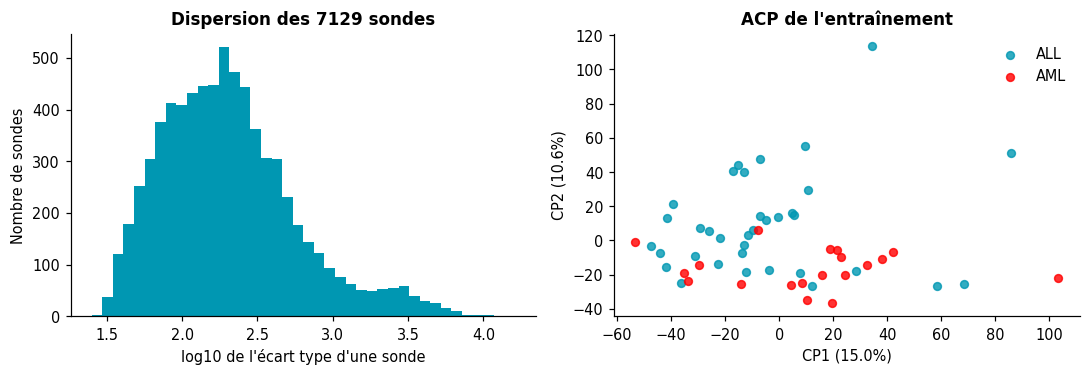

In [6]:
sc = StandardScaler().fit(X_train)
pca = PCA(n_components=10, random_state=SEED).fit(sc.transform(X_train))
P = pca.transform(sc.transform(X_train))
print("variance expliquée par les 5 premières composantes :", pca.explained_variance_ratio_[:5].round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(np.log10(ecart), bins=40, color=CYAN)
axes[0].set_xlabel("log10 de l'écart type d'une sonde"); axes[0].set_ylabel("Nombre de sondes")
axes[0].set_title("Dispersion des 7129 sondes")
for classe, couleur, nom in [(0, CYAN, "ALL"), (1, ROUGE, "AML")]:
    m = (y_train == classe).values
    axes[1].scatter(P[m, 0], P[m, 1], color=couleur, s=26, alpha=0.8, label=nom)
axes[1].set_xlabel(f"CP1 ({pca.explained_variance_ratio_[0]:.1%})"); axes[1].set_ylabel(f"CP2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[1].set_title("ACP de l'entraînement"); axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fig_golub_exploration.png", dpi=170, bbox_inches="tight")
plt.show()
JOURNAL["acp_variance_cp1_cp2"] = [round(float(pca.explained_variance_ratio_[0]), 4), round(float(pca.explained_variance_ratio_[1]), 4)]

L'analyse en composantes principales est **non supervisée** : elle ne connaît pas les classes, qui ne servent ici qu'à colorer les points. Une séparation partielle visible dans les deux premières composantes indique que le signal est suffisamment structuré pour être appris, sans garantir que les classes soient linéairement séparables dans l'espace complet.

## 5. La fuite par sélection de variables : démonstration

La sélection de gènes **utilise les étiquettes** (par exemple un test statistique entre classes). Si on l'exécute sur l'ensemble des données *avant* la validation croisée, les gènes retenus ont été choisis en voyant aussi les échantillons de validation : le score est biaisé, parfois spectaculairement quand $p \gg n$.

**Expérience de contrôle.** On **permute aléatoirement** les étiquettes de l'entraînement : il n'existe alors aucune relation entre expression et classe, et la seule performance honnête possible est celle du hasard (AUC de 0,5). On compare deux procédures, répétées sur 20 permutations :

* **fautive** : sélection de 50 gènes sur tout l'entraînement, puis validation croisée du modèle ;
* **correcte** : sélection placée dans le `Pipeline`, donc recalculée à chaque pli sur ses seules données d'entraînement.

étiquettes permutées | AUC procédure fautive  : 0.969 (min 0.921, max 1.000)
étiquettes permutées | AUC procédure correcte : 0.478 (min 0.269, max 0.743)


étiquettes réelles   | AUC fautive : 1.000 | AUC correcte : 0.964


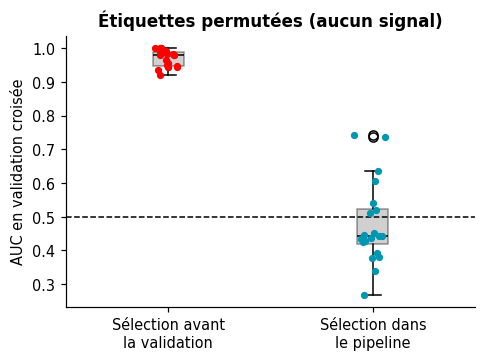

In [7]:
def pipeline_selection(k=50, C=0.1):
    return Pipeline([("scaler", StandardScaler()), ("selection", SelectKBest(f_classif, k=k)),
                     ("modele", LogisticRegression(C=C, max_iter=2000))])

cv_demo = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rng = np.random.default_rng(SEED)
auc_faute, auc_correct = [], []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for _ in range(20):
        yp = pd.Series(rng.permutation(y_train.values), index=y_train.index)
        # procédure fautive : la sélection voit toutes les étiquettes
        Xs = SelectKBest(f_classif, k=50).fit_transform(StandardScaler().fit_transform(X_train), yp)
        auc_faute.append(cross_val_score(LogisticRegression(C=0.1, max_iter=2000), Xs, yp, cv=cv_demo, scoring="roc_auc").mean())
        # procédure correcte
        auc_correct.append(cross_val_score(pipeline_selection(), X_train, yp, cv=cv_demo, scoring="roc_auc").mean())

print(f"étiquettes permutées | AUC procédure fautive  : {np.mean(auc_faute):.3f} (min {np.min(auc_faute):.3f}, max {np.max(auc_faute):.3f})")
print(f"étiquettes permutées | AUC procédure correcte : {np.mean(auc_correct):.3f} (min {np.min(auc_correct):.3f}, max {np.max(auc_correct):.3f})")

# Étiquettes réelles : l'écart est beaucoup plus faible car il existe un vrai signal.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    Xs = SelectKBest(f_classif, k=50).fit_transform(StandardScaler().fit_transform(X_train), y_train)
    reel_faute = cross_val_score(LogisticRegression(C=0.1, max_iter=2000), Xs, y_train, cv=cv_demo, scoring="roc_auc").mean()
    reel_correct = cross_val_score(pipeline_selection(), X_train, y_train, cv=cv_demo, scoring="roc_auc").mean()
print(f"étiquettes réelles   | AUC fautive : {reel_faute:.3f} | AUC correcte : {reel_correct:.3f}")

fig, ax = plt.subplots(figsize=(4.8, 3.2))
ax.boxplot([auc_faute, auc_correct], tick_labels=["Sélection avant\nla validation", "Sélection dans\nle pipeline"], patch_artist=True,
           boxprops=dict(facecolor=GRIS, alpha=0.4), medianprops=dict(color=NOIR))
for i, vals, c in [(1, auc_faute, ROUGE), (2, auc_correct, CYAN)]:
    ax.scatter(np.full(len(vals), i) + rng.normal(0, 0.04, len(vals)), vals, color=c, s=14, zorder=3)
ax.axhline(0.5, color=NOIR, ls="--", lw=1)
ax.set_ylabel("AUC en validation croisée"); ax.set_title("Étiquettes permutées (aucun signal)")
fig.savefig(FIG / "fig_fuite_selection.png", dpi=170, bbox_inches="tight")
plt.show()
JOURNAL["fuite_selection"] = {"permutation_fautive": [round(float(np.mean(auc_faute)), 4), round(float(np.min(auc_faute)), 4), round(float(np.max(auc_faute)), 4)],
                              "permutation_correcte": [round(float(np.mean(auc_correct)), 4), round(float(np.min(auc_correct)), 4), round(float(np.max(auc_correct)), 4)],
                              "reel_fautive": round(float(reel_faute), 4), "reel_correcte": round(float(reel_correct), 4)}

Avec des étiquettes sans aucun lien avec les données, la procédure fautive annonce une AUC très supérieure au hasard : la sélection a « trouvé » des gènes qui séparent par accident les échantillons, puis la validation, qui n'est plus indépendante, a récompensé ce biais. La procédure correcte reste autour de 0,5, ce qui est la seule réponse honnête. **Règle opérationnelle : toute étape qui utilise l'étiquette (sélection de variables, réduction supervisée, choix de seuil) appartient au pipeline.**

## 6. Modèles candidats et comparaison par validation croisée imbriquée

Avec 54 échantillons d'entraînement, un seul découpage entraînement/validation serait très bruité. On évalue donc chaque *procédure complète* (prétraitement, sélection, réglage des hyperparamètres) par une validation croisée **imbriquée** : boucle externe répétée pour estimer, boucle interne pour régler.

| Candidat | Description | Hyperparamètres réglés |
|---|---|---|
| Référence | prédit la classe majoritaire | aucun |
| Logistique, tous les gènes | mise à l'échelle puis régression logistique régularisée sur 7129 sondes | `C` |
| Sélection de gènes + logistique | mise à l'échelle, `SelectKBest` (test F), régression logistique | `k`, `C` |
| Forêt aléatoire | 300 arbres sur toutes les sondes, sans mise à l'échelle | aucun (valeurs par défaut) |

L'AUC est le critère de sélection interne. On suit aussi le rappel de la classe AML et la balanced accuracy, plus informative que l'accuracy en classes déséquilibrées.

In [8]:
cv_externe = RepeatedStratifiedKFold(n_splits=4, n_repeats=3, random_state=SEED)
cv_interne = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED + 1)
scoring_ext = {"roc_auc": "roc_auc", "recall": "recall", "balanced_accuracy": "balanced_accuracy"}

pipe_tous = Pipeline([("scaler", StandardScaler()), ("modele", LogisticRegression(max_iter=3000))])
grille_tous = {"modele__C": [0.0001, 0.001, 0.01, 0.1]}
pipe_sel = Pipeline([("scaler", StandardScaler()), ("selection", SelectKBest(f_classif)), ("modele", LogisticRegression(max_iter=3000))])
grille_sel = {"selection__k": [5, 20, 100, 500], "modele__C": [0.01, 0.1, 1]}
pipe_rf = Pipeline([("modele", RandomForestClassifier(n_estimators=300, random_state=SEED))])
pipe_ref = Pipeline([("modele", DummyClassifier(strategy="most_frequent"))])

candidats = {
    "Référence": pipe_ref,
    "Logistique, tous les gènes": GridSearchCV(pipe_tous, grille_tous, scoring="roc_auc", cv=cv_interne),
    "Sélection de gènes + logistique": GridSearchCV(pipe_sel, grille_sel, scoring="roc_auc", cv=cv_interne),
    "Forêt aléatoire": pipe_rf,
}
nested = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for nom, est in candidats.items():
        r = cross_validate(est, X_train, y_train, cv=cv_externe, scoring=scoring_ext)
        nested[nom] = {m: (r["test_" + m].mean(), r["test_" + m].std()) for m in scoring_ext}
tab_nested = pd.DataFrame({n: {m: f"{mu:.3f} ± {sd:.3f}" for m, (mu, sd) in d.items()} for n, d in nested.items()}).T
print(tab_nested)
JOURNAL["imbriquee"] = {n: {m: [round(float(mu), 4), round(float(sd), 4)] for m, (mu, sd) in d.items()} for n, d in nested.items()}

                                       roc_auc         recall  \
Référence                        0.500 ± 0.000  0.000 ± 0.000   
Logistique, tous les gènes       0.974 ± 0.039  0.829 ± 0.198   
Sélection de gènes + logistique  0.972 ± 0.044  0.867 ± 0.189   
Forêt aléatoire                  0.989 ± 0.024  0.854 ± 0.221   

                                balanced_accuracy  
Référence                           0.500 ± 0.000  
Logistique, tous les gènes          0.886 ± 0.101  
Sélection de gènes + logistique     0.923 ± 0.095  
Forêt aléatoire                     0.927 ± 0.111  


**Lecture.** Les écarts types portent sur 12 plis externes dont chacun contient environ 13 échantillons : ils sont **importants**, et les plis ne sont pas indépendants (ils partagent des échantillons d'entraînement). Les intervalles `±` sont donc des indications de dispersion, non des intervalles de confiance.

## 7. Sélection du modèle final par une règle fixée à l'avance

**Règle.** On retient le candidat d'AUC moyenne maximale. Parmi les candidats dont l'AUC moyenne est à moins d'un écart type de celle du meilleur, on retient le plus parcimonieux selon l'ordre : sélection de gènes + logistique, logistique sur tous les gènes, forêt aléatoire. Un modèle qui s'appuie sur peu de gènes est plus facile à examiner, à répliquer et à interpréter.

In [9]:
ordre_parcimonie = ["Sélection de gènes + logistique", "Logistique, tous les gènes", "Forêt aléatoire"]
auc = {n: nested[n]["roc_auc"] for n in ordre_parcimonie}
meilleur = max(auc, key=lambda n: auc[n][0])
seuil_auc = auc[meilleur][0] - auc[meilleur][1]
eligibles = [n for n in ordre_parcimonie if auc[n][0] >= seuil_auc]
choix = eligibles[0]
print("AUC imbriquée :", {n: round(float(auc[n][0]), 4) for n in ordre_parcimonie})
print("meilleur :", meilleur, "| candidats à moins d'un écart type :", eligibles)
print("modèle retenu :", choix)
JOURNAL["choix"] = {"meilleur_auc": meilleur, "eligibles": eligibles, "retenu": choix}

AUC imbriquée : {'Sélection de gènes + logistique': 0.972, 'Logistique, tous les gènes': 0.9738, 'Forêt aléatoire': 0.9892}
meilleur : Forêt aléatoire | candidats à moins d'un écart type : ['Sélection de gènes + logistique', 'Logistique, tous les gènes', 'Forêt aléatoire']
modèle retenu : Sélection de gènes + logistique


Le réglage des hyperparamètres du modèle retenu est refait sur **tout** l'entraînement avec une validation croisée répétée, puis le modèle est réajusté. Aucune donnée de test n'intervient.

In [10]:
cv_reglage = RepeatedStratifiedKFold(n_splits=4, n_repeats=5, random_state=SEED + 2)
reglage = {"Logistique, tous les gènes": (pipe_tous, grille_tous),
           "Sélection de gènes + logistique": (pipe_sel, grille_sel),
           "Forêt aléatoire": (pipe_rf, {"modele__max_features": ["sqrt", 0.05]})}[choix]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    gs = GridSearchCV(reglage[0], reglage[1], scoring="roc_auc", cv=cv_reglage).fit(X_train, y_train)
modele_final = gs.best_estimator_
print("meilleurs hyperparamètres :", gs.best_params_)
print(f"AUC de validation croisée répétée (optimiste, car utilisée pour choisir) : {gs.best_score_:.4f}")
JOURNAL["reglage"] = {"params": {k: (v.item() if hasattr(v, "item") else v) for k, v in gs.best_params_.items()}, "auc_cv_optimiste": round(float(gs.best_score_), 4)}

meilleurs hyperparamètres : {'modele__C': 0.1, 'selection__k': 500}
AUC de validation croisée répétée (optimiste, car utilisée pour choisir) : 0.9860


Le nombre de gènes retenu par le réglage peut être élevé : la parcimonie n'a servi qu'à **départager** des candidats équivalents, elle ne garantit pas un modèle à quelques gènes.

## 8. Évaluation finale, unique, sur le jeu de test

Le jeu de test contient 18 échantillons dont 6 AML. **Chaque échantillon pèse environ 5,6 points d'accuracy et 16,7 points de rappel de la classe AML.** Les estimations seront donc très imprécises ; des intervalles de confiance **exacts** (Clopper-Pearson, adaptés aux proportions sur petit effectif) en rendent compte. Un bootstrap serait inadapté si tous les échantillons de test sont bien classés.

accuracy     1.0
precision    1.0
recall       1.0
f1           1.0
roc_auc      1.0
VN=12 FP=0 FN=0 VP=6
référence (toujours ALL) sur ce test : accuracy = 0.667
accuracy    IC95 % exact (Clopper-Pearson) = [0.815 ; 1.000]
recall      IC95 % exact (Clopper-Pearson) = [0.541 ; 1.000]
specificity IC95 % exact (Clopper-Pearson) = [0.735 ; 1.000]
AUC : un bootstrap serait dégénéré (toutes les ré-échantillons parfaits) et donnerait une fausse impression de certitude.


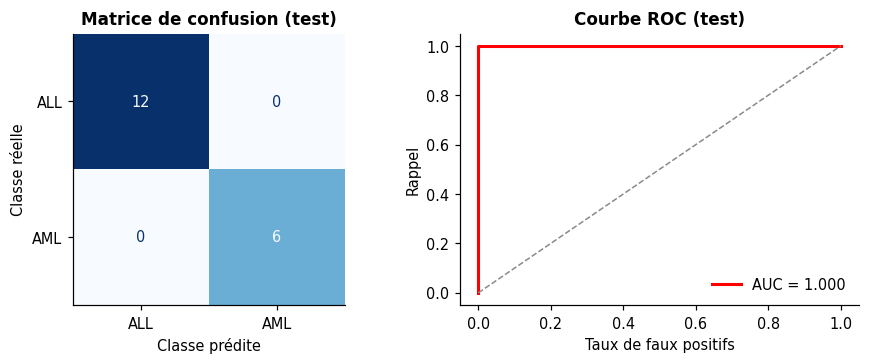

In [11]:
proba = modele_final.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
assert pred.shape == (len(X_test),) and np.array_equal(pred, modele_final.predict(X_test))

mf = {"accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred, zero_division=0),
      "recall": recall_score(y_test, pred, zero_division=0), "f1": f1_score(y_test, pred, zero_division=0),
      "roc_auc": roc_auc_score(y_test, proba)}
print(pd.Series(mf).round(3).to_string())
vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
print(f"VN={vn} FP={fp} FN={fn} VP={vp}")
print("référence (toujours ALL) sur ce test : accuracy =", round(1 - y_test.mean(), 3))

from scipy.stats import beta

def clopper_pearson(k, n, alpha=0.05):
    """Intervalle de confiance exact d'une proportion binomiale k / n."""
    bas = 0.0 if k == 0 else float(beta.ppf(alpha / 2, k, n - k + 1))
    haut = 1.0 if k == n else float(beta.ppf(1 - alpha / 2, k + 1, n - k))
    return bas, haut

yt = y_test.values
ic = {"accuracy": clopper_pearson(int((pred == yt).sum()), len(yt)),
      "recall": clopper_pearson(int(((pred == 1) & (yt == 1)).sum()), int(yt.sum())),
      "specificity": clopper_pearson(int(((pred == 0) & (yt == 0)).sum()), int((yt == 0).sum()))}
for k, (a, b) in ic.items():
    print(f"{k:11s} IC95 % exact (Clopper-Pearson) = [{a:.3f} ; {b:.3f}]")
print("AUC : un bootstrap serait dégénéré (toutes les ré-échantillons parfaits) et donnerait une fausse impression de certitude.")
JOURNAL["test"] = {"metriques": {k: round(float(v), 4) for k, v in mf.items()}, "confusion": {"VN": int(vn), "FP": int(fp), "FN": int(fn), "VP": int(vp)},
                   "ic95_exact": {k: [round(a, 4), round(b, 4)] for k, (a, b) in ic.items()}, "n_test": int(len(yt)), "n_aml_test": int(yt.sum())}

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["ALL", "AML"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Matrice de confusion (test)"); axes[0].grid(False)
axes[0].set_xlabel("Classe prédite"); axes[0].set_ylabel("Classe réelle")
fpr, tpr, _ = roc_curve(y_test, proba)
axes[1].plot(fpr, tpr, color=ROUGE, lw=2, label=f"AUC = {mf['roc_auc']:.3f}")
axes[1].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)
axes[1].set_xlabel("Taux de faux positifs"); axes[1].set_ylabel("Rappel"); axes[1].set_title("Courbe ROC (test)")
axes[1].legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "fig_golub_test.png", dpi=170, bbox_inches="tight")
plt.show()

**Lecture prudente d'un score parfait.** Un résultat de 18 sur 18 sur un test minuscule est compatible avec une performance réelle sensiblement plus faible : l'intervalle exact pour le rappel de la classe AML (6 sur 6) reste très large. La validation croisée imbriquée du même pipeline donnait un rappel moyen nettement inférieur à 1 avec un grand écart type : **c'est cette estimation, plus riche, qui décrit la performance attendue**, et non le score du test. Le test confirme l'absence de problème grossier, rien de plus.

## 9. Quels gènes ? Stabilité de la sélection

Les sondes retenues par le modèle sont des **candidats statistiques**, pas des gènes validés. Leur identité n'est pas annotée dans ce fichier : relier un identifiant de sonde à un gène exige le fichier d'annotation de la plateforme, qui n'est pas fourni ici. On évalue plutôt la **stabilité** de la sélection : si de légères modifications de l'échantillon changent profondément la liste, la liste n'est pas fiable. On mesure le recouvrement (indice de Jaccard) des 20 meilleures sondes entre 20 sous-échantillons de 80 % de l'entraînement.

In [12]:
def top_sondes(Xa, ya, k=20):
    Xa_s = StandardScaler().fit_transform(Xa)
    scores, _ = f_classif(Xa_s, ya)
    return set(np.argsort(np.nan_to_num(scores))[::-1][:k])

rng = np.random.default_rng(SEED)
ensembles = []
for _ in range(20):
    idx = np.concatenate([rng.choice(np.where(y_train.values == c)[0], size=int(0.8 * (y_train.values == c).sum()), replace=False) for c in (0, 1)])
    ensembles.append(top_sondes(X_train.values[idx], y_train.values[idx]))
jaccards = [len(a & b) / len(a | b) for i, a in enumerate(ensembles) for b in ensembles[i + 1:]]
frequence = pd.Series(np.concatenate([list(e) for e in ensembles])).value_counts()
print(f"indice de Jaccard moyen entre listes de 20 sondes : {np.mean(jaccards):.3f}")
print("sondes présentes dans au moins 18 listes sur 20 :", int((frequence >= 18).sum()))
print("identifiants des 5 sondes les plus fréquentes :", [X.columns[i] for i in frequence.index[:5]])
JOURNAL["stabilite"] = {"jaccard_moyen": round(float(np.mean(jaccards)), 4), "sondes_frequentes_18_sur_20": int((frequence >= 18).sum())}

indice de Jaccard moyen entre listes de 20 sondes : 0.452
sondes présentes dans au moins 18 listes sur 20 : 8
identifiants des 5 sondes les plus fréquentes : ['M22960_at', 'M23197_at', 'M63138_at', 'M27891_at', 'X17042_at']


Un indice de Jaccard proche de 1 indiquerait une liste très stable ; une valeur autour de 0,5 signifie que près de la moitié des sondes changent d'un sous-échantillon à l'autre, tandis qu'un petit noyau de sondes revient presque toujours. Cette stabilité partielle est typique des données où de nombreuses sondes sont corrélées et informatives ; elle ne dit rien du rôle biologique de ces sondes. Pour passer de la liste à la biologie, il faudrait annoter les sondes, tester l'enrichissement fonctionnel et surtout répliquer dans une cohorte indépendante.

## 10. Sauvegarde, rechargement et prédiction sur un échantillon inconnu

In [13]:
joblib.dump(modele_final, MOD / "modele_golub.joblib")
(MOD / "modele_golub_metadonnees.json").write_text(json.dumps({
    "modele": choix, "sklearn": sklearn.__version__, "classe_positive": "AML (1)", "nombre_sondes_attendues": int(X.shape[1]),
    "hyperparametres": JOURNAL["reglage"]["params"], "graine": SEED, "source_donnees": URL, "sha256": sha}, ensure_ascii=False, indent=2))

recharge = joblib.load(MOD / "modele_golub.joblib")
assert np.array_equal(recharge.predict(X_test), modele_final.predict(X_test))
assert np.allclose(recharge.predict_proba(X_test), modele_final.predict_proba(X_test))

inconnu = X_test.iloc[[0]]
print("échantillon", inconnu.index[0], "| probabilité d'AML :", round(float(recharge.predict_proba(inconnu)[0, 1]), 4), "| vérité :", "AML" if y_test.iloc[0] else "ALL")
try:
    recharge.predict(inconnu.iloc[:, :100])
except ValueError as e:
    print("entrée incomplète refusée :", str(e).splitlines()[0])
(RES / "nb07.json").write_text(json.dumps(JOURNAL, ensure_ascii=False, indent=2, default=str))
print("Journal enregistré.")

échantillon 9 | probabilité d'AML : 0.0024 | vérité : ALL
entrée incomplète refusée : The feature names should match those that were passed during fit.
Journal enregistré.


## 11. Bilan critique et limites

* **Effectif.** 72 échantillons au total, 18 en test : les intervalles de confiance sont larges et l'estimation du rappel de la classe AML repose sur 6 échantillons. Ces résultats ne permettent ni de classer finement les modèles, ni d'exclure une performance sensiblement inférieure.
* **Tâche facile.** La distinction ALL contre AML est un problème de référence connu pour être relativement séparable : une bonne performance ne dit rien de la difficulté de tâches plus subtiles (sous-types, pronostic, réponse thérapeutique).
* **Structure inconnue.** Les métadonnées des échantillons (centre d'origine, tissu, sexe) ne sont pas dans ce fichier. Un effet de lot confondu avec la classe ne peut donc pas être détecté ni corrigé ici.
* **Validité externe.** Aucune cohorte indépendante n'est utilisée. Une performance interne n'établit pas la validité clinique.
* **Association et mécanisme.** Les sondes sélectionnées sont associées statistiquement à la classe. Cela ne prouve pas un rôle causal.
* **Source de données.** La copie utilisée est un miroir public dont la licence n'a pas été vérifiée.
* **Deep learning.** Un réseau dense sur 7129 entrées avec 54 échantillons aurait plus de 100 000 paramètres à estimer : le contexte est défavorable, il n'a donc pas été utilisé.

## 12. Exercices progressifs

**Exercice 1.** Quelle proportion de la variance totale (standardisée) les dix premières composantes de l'ACP expliquent-elles ? Que dit ce chiffre de la dimension effective des données ?

*Solution de l'exercice 1*

In [14]:
cumul = pca.explained_variance_ratio_.cumsum()
print("variance cumulée expliquée par 10 composantes :", round(float(cumul[-1]), 3))
assert 0 < cumul[-1] < 1

variance cumulée expliquée par 10 composantes : 0.527


**Exercice 2.** Évaluez par validation croisée l'effet de `k` (5, 20, 100, 500) sur l'AUC du pipeline de sélection, avec `C = 0.1`. Y a-t-il un nombre de gènes nettement meilleur ?

*Solution de l'exercice 2*

In [15]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for k in (5, 20, 100, 500):
        s = cross_val_score(pipeline_selection(k=k, C=0.1), X_train, y_train, cv=cv_externe, scoring="roc_auc")
        print(f"k = {k:3d} | AUC = {s.mean():.3f} ± {s.std():.3f}")

k =   5 | AUC = 0.968 ± 0.034


k =  20 | AUC = 0.949 ± 0.065


k = 100 | AUC = 0.972 ± 0.038


k = 500 | AUC = 0.981 ± 0.048


**Exercice 3.** Réalisez un test de permutation du modèle retenu : permutez 10 fois les étiquettes d'entraînement, évaluez l'AUC par validation croisée, et comparez à l'AUC obtenue avec les vraies étiquettes.

*Solution de l'exercice 3*

In [16]:
rng = np.random.default_rng(1)
cv_p = StratifiedKFold(4, shuffle=True, random_state=SEED)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    nulle = [cross_val_score(modele_final, X_train, pd.Series(rng.permutation(y_train.values), index=y_train.index), cv=cv_p, scoring="roc_auc").mean() for _ in range(10)]
    vraie = cross_val_score(modele_final, X_train, y_train, cv=cv_p, scoring="roc_auc").mean()
print(f"AUC avec vraies étiquettes : {vraie:.3f} | AUC sous permutation : moyenne {np.mean(nulle):.3f}, maximum {np.max(nulle):.3f}")
assert vraie > np.max(nulle)

AUC avec vraies étiquettes : 0.994 | AUC sous permutation : moyenne 0.501, maximum 0.699


**Exercice 4 (extension).** Reproduisez la démarche sur une série d'expression issue de NCBI GEO (par exemple avec le paquet `GEOparse`) : choisissez une série comportant deux groupes cliniques, vérifiez la structure, et comparez vos résultats à ceux de ce notebook. Documentez la provenance, la licence et la plateforme de mesure.

## 13. Synthèse des compétences acquises

Ce projet mobilise l'ensemble du parcours :

| Étape du pipeline | Mise en oeuvre dans ce notebook |
|---|---|
| Contrôle qualité | dimensions, doublons, valeurs manquantes, échelles, cible absente des caractéristiques |
| Exploration | dispersion des sondes, ACP sur l'entraînement uniquement |
| Définition de la cible | AML en classe positive, déséquilibre 47 / 25 pris en compte |
| Partitionnement | stratifié, test réservé avant toute exploration supervisée |
| Prétraitement | mise à l'échelle et sélection de gènes dans le pipeline |
| Validation et optimisation | validation croisée imbriquée, règle de choix écrite à l'avance |
| Évaluation finale | une seule fois, intervalles de confiance par bootstrap |
| Interprétation | stabilité des gènes, distinction prédiction, association, mécanisme |
| Sauvegarde et prédiction | pipeline sérialisé, rechargé, vérifié |